# Code Testing pipeline NEO-FD1

A small, end-to-end run of the thesis pipeline on **real data**, to check that every step works:

1. Load real Sentinel-2 chips with labels: **Sen1Floods11** (water) and **CloudSEN12** (cloud).
2. Cut them into 16×16 patches and compute patch labels.
3. Split **by group** and normalise with **training statistics only**.
4. Extract teacher features $t\in\mathbb R^{768}$ with the frozen **Copernicus-FM** (one patch = one token).
5. **Phase 1**: distil a tiny CNN student ($s\in\mathbb R^{64}$) with **cosine** and with **MSE**.
6. **Phase 2**: two linear heads, multi-task cross-entropy, at two label fractions, vs a baseline trained from scratch.
7. **Metrics**: TPR at 1% FPR (threshold on validation), F1, PR-AUC, and $\Delta$ with a group bootstrap.
8. **Size budget and INT8 PTQ** (Eq. 7): per-tensor vs per-channel, compared with INT4.

In [2]:
import io, numpy as np, pandas as pd, requests, rasterio, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score, roc_curve
dev = "cuda" if torch.cuda.is_available() else "cpu"
rng = np.random.default_rng(0); torch.manual_seed(0)

# ---- parameters of the thesis (Sections 2.7, 3.4) ----
P = 16                        # patch size (pixels)
B = 64                        # student embedding size b
TAU, TAUS = 0.25, [0.05, 0.25, 0.5]   # coverage threshold used for training, and values reported
V_MIN = 0.9                   # minimum valid fraction of a patch
MAX_PATCHES = 256             # patches kept per chip (to stay small)
N_CHIPS = {"train": 20, "val": 8, "test": 12}   # chips per split and dataset
LABEL_FRACTIONS = [0.25, 1.0] # fractions of labelled training groups (nested)
M_BYTES = 100 * 1024          # example on-board memory M for the budget check (Eq. 7)
FPR_TARGET = 0.01             # false-positive rate at which TPR is reported
# Sentinel-2 L1C, 13 bands in the order B01..B12 (with B8A after B08); wavelength and bandwidth in nm
BANDS = ["B01","B02","B03","B04","B05","B06","B07","B08","B8A","B09","B10","B11","B12"]
WAVE  = [443, 490, 560, 665, 705, 740, 783, 842, 865, 945, 1375, 1610, 2190]
BW    = [ 20,  65,  35,  30,  15,  15,  20, 115,  20,  20,   30,   90,  180]
print("device:", dev)

device: cpu


## 1. Real data
**Sen1Floods11** — hand-labelled chips (512×512 px, 13 bands, labels −1 no data / 0 / 1 water)

**CloudSEN12** — high-quality L1C image patches (509×509 px, 13 bands, labels 0 clear / 1 thick / 2 thin / 3 shadow)

In [3]:
S1F = "https://storage.googleapis.com/sen1floods11/v1.1"

def read_tif(url):
    with rasterio.open(io.BytesIO(requests.get(url, timeout=120).content)) as f:
        return f.read()

def load_sen1floods11():
    chips = []
    for split, csv in [("train", "train"), ("val", "valid"), ("test", "test")]:
        names = pd.read_csv(f"{S1F}/splits/flood_handlabeled/flood_{csv}_data.csv", header=None)[0]
        for name in rng.permutation(names)[:N_CHIPS[split]]:
            cid = name.replace("_S1Hand.tif", "")
            img = read_tif(f"{S1F}/data/flood_events/HandLabeled/S2Hand/{cid}_S2Hand.tif").astype(np.float32)
            lab = read_tif(f"{S1F}/data/flood_events/HandLabeled/LabelHand/{cid}_LabelHand.tif")[0]
            chips.append(dict(task="water", split=split, group=cid, img=img, mask=(lab == 1), valid=(lab != -1)))
    return chips

water_chips = load_sen1floods11()
print(len(water_chips), "Sen1Floods11 chips, image shape", water_chips[0]["img"].shape)

40 Sen1Floods11 chips, image shape (13, 512, 512)


In [4]:
import tacoreader                       # v0.x, reads the TACO v1 format of CloudSEN12

def load_cloudsen12():
    ds = tacoreader.load("tacofoundation:cloudsen12-l1c")
    ds = ds[(ds["label_type"] == "high") & (ds["real_proj_shape"] == 509)]
    split_col = "tortilla:data_split"
    group_col = "roi_id" if "roi_id" in ds.columns else "tortilla:id"
    chips = []
    for split, name in [("train", "train"), ("val", "validation"), ("test", "test")]:
        sub = ds[ds[split_col] == name]
        rois = rng.permutation(sub[group_col].unique())[:N_CHIPS[split]]
        for roi in rois:
            i = sub.index[sub[group_col] == roi][0]           # one image per ROI keeps it small
            sample = ds.read(int(np.where(ds.index == i)[0][0]))
            with rasterio.open(sample.read(0)) as f: img = f.read().astype(np.float32)
            with rasterio.open(sample.read(1)) as f: lab = f.read(1)
            chips.append(dict(task="cloud", split=split, group=str(roi), img=img,
                              mask=np.isin(lab, [1, 2]), valid=np.ones_like(lab, bool)))
    return chips

cloud_chips = load_cloudsen12()
print(len(cloud_chips), "CloudSEN12 chips, image shape", cloud_chips[0]["img"].shape)

2026-11-05 16:57:10,202 - WARNING - CPLE_AppDefined in PROJ: proj_create_from_database: C:\Program Files\PostgreSQL\14\share\contrib\postgis-3.4\proj\proj.db contains DATABASE.LAYOUT.VERSION.MINOR = 2 whereas a number >= 6 is expected. It comes from another PROJ installation.
2026-11-05 16:57:10,205 - WARNING - CPLE_AppDefined in The definition of projected CRS EPSG:32642 got from GeoTIFF keys is not the same as the one from the EPSG registry, which may cause issues during reprojection operations. Set GTIFF_SRS_SOURCE configuration option to EPSG to use official parameters (overriding the ones from GeoTIFF keys), or to GEOKEYS to use custom values from GeoTIFF keys and drop the EPSG code.
2026-11-05 16:57:10,205 - WARNING - CPLE_AppDefined in PROJ: proj_create_from_name: C:\Program Files\PostgreSQL\14\share\contrib\postgis-3.4\proj\proj.db contains DATABASE.LAYOUT.VERSION.MINOR = 2 whereas a number >= 6 is expected. It comes from another PROJ installation.
2026-11-05 16:57:11,664 - WAR

40 CloudSEN12 chips, image shape (13, 512, 512)


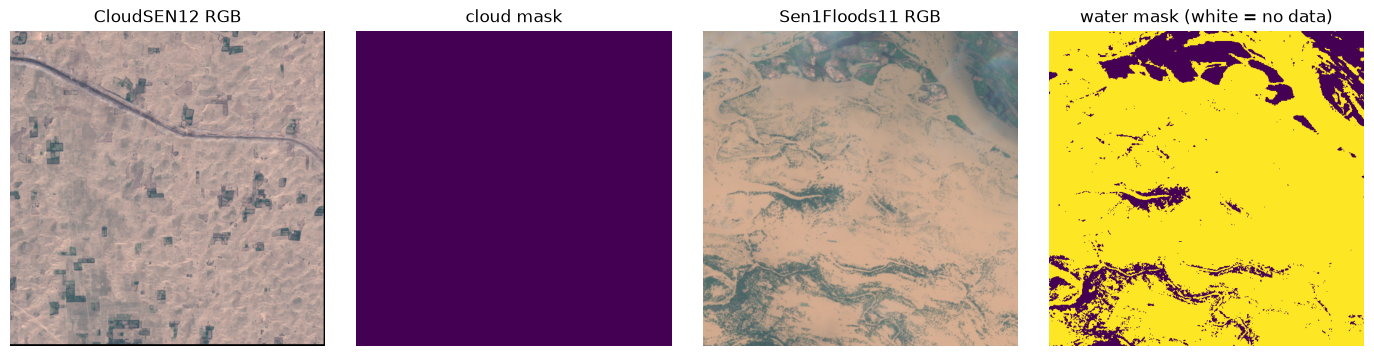

In [5]:
c, w = cloud_chips[0], water_chips[0]
rgb = lambda im: np.clip(im[[3, 2, 1]].transpose(1, 2, 0) / 3000, 0, 1)
fig, ax = plt.subplots(1, 4, figsize=(14, 3.5))
ax[0].imshow(rgb(c["img"])); ax[0].set_title("CloudSEN12 RGB")
ax[1].imshow(c["mask"]); ax[1].set_title("cloud mask")
ax[2].imshow(rgb(w["img"])); ax[2].set_title("Sen1Floods11 RGB")
ax[3].imshow(np.where(w["valid"], w["mask"], np.nan)); ax[3].set_title("water mask (white = no data)")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

## 2. Patches and patch labels
Each chip is cut into non-overlapping 16×16 patches

patches: (20224, 13, 16, 16)

share of positive patches for each tau:
       tau=0.05  tau=0.25  tau=0.5
task                              
cloud     0.381     0.351    0.319
water     0.226     0.169    0.136


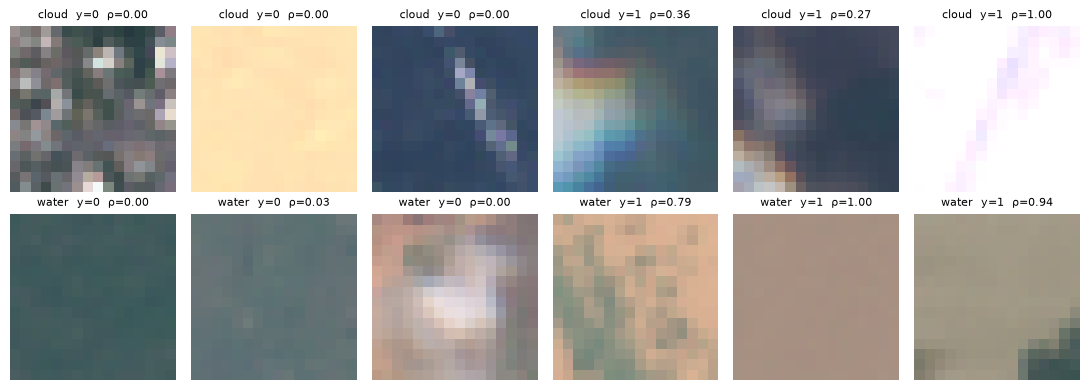

In [18]:
def patchify(chip):
    C, H, W = chip["img"].shape
    nh, nw = H // P, W // P
    cut = lambda a: a[..., :nh*P, :nw*P].reshape(*a.shape[:-2], nh, P, nw, P).swapaxes(-3, -2).reshape(*a.shape[:-2], nh*nw, P, P)
    x = np.moveaxis(cut(chip["img"]), -3, 0)                       # (N, C, 16, 16)
    nodata = (chip["img"].sum(0) == 0)                             # pixels where all bands are zero
    m, val = cut(chip["mask"].astype(np.float32)), cut((chip["valid"] & ~nodata).astype(np.float32))
    v = val.mean((1, 2))                                           # Eq. 1: valid fraction
    rho = (m * val).sum((1, 2)) / np.maximum(val.sum((1, 2)), 1)   # Eq. 1: covered fraction
    keep = np.where(v >= V_MIN)[0]
    keep = rng.permutation(keep)[:MAX_PATCHES]
    return x[keep], rho[keep]

def hotspot_label(box_mask_patch, n_min):                          # Eq. 3 (THRawS), boxes rasterised to a 0/1 mask
    return int(box_mask_patch.sum() >= n_min)

rows, X = [], []
for chip in cloud_chips + water_chips:
    x, rho = patchify(chip)
    X.append(x)
    rows += [dict(task=chip["task"], split=chip["split"], group=chip["group"], rho=r) for r in rho]
X = np.concatenate(X).astype(np.float32)
meta = pd.DataFrame(rows)
meta["y"] = (meta.rho >= TAU).astype(int)                          # Eq. 2: positive if rho >= tau
print("patches:", X.shape)
print("\nshare of positive patches for each tau:")
print(pd.DataFrame({f"tau={t}": meta.groupby("task").rho.apply(lambda r: (r >= t).mean()) for t in TAUS}).round(3))

# ---- plot: 3 negative and 3 positive patches per task ----
patch_rgb = lambda p: np.clip(p[[3, 2, 1]].transpose(1, 2, 0) / 3000, 0, 1)   # bands B04, B03, B02
fig, ax = plt.subplots(2, 6, figsize=(11, 4))
for r, task in enumerate(["cloud", "water"]):
    sel = meta.index[meta.task == task]
    neg, pos = sel[meta.loc[sel, "y"] == 0], sel[meta.loc[sel, "y"] == 1]
    ids = list(rng.choice(neg, min(3, len(neg)), replace=False)) + list(rng.choice(pos, min(3, len(pos)), replace=False))
    for c, i in enumerate(ids):
        ax[r, c].imshow(patch_rgb(X[i]))
        ax[r, c].set_title(f"{task}  y={meta.y[i]}  ρ={meta.rho[i]:.2f}", fontsize=8)
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

## 3. Group splits, normalisation, leakage check

In [7]:
grp_split = meta.groupby("group").split.nunique()
assert (grp_split == 1).all(), "leakage: a group is in two splits"
print("check (a) passed: every group is in exactly one split")

tr = (meta.split == "train").values
mean = X[tr].mean((0, 2, 3), keepdims=True); std = X[tr].std((0, 2, 3), keepdims=True) + 1e-6
Xn = torch.tensor((X - mean) / std)                                # student input, training statistics only

train_groups = rng.permutation(meta[tr].group.unique())
labelled = {f: set(train_groups[:max(1, int(round(f * len(train_groups))))]) for f in LABEL_FRACTIONS}
for f in LABEL_FRACTIONS: print(f"label fraction {f:.0%}: {len(labelled[f])} groups")

check (a) passed: every group is in exactly one split
label fraction 25%: 10 groups
label fraction 100%: 40 groups


## 4. Teacher features with Copernicus-FM
Frozen Copernicus-FM ViT-Base from TorchGeo. A 16×16 patch with kernel size 16 gives **one image token**; with the CLS token the sequence has two tokens, and the output is $t\in\mathbb R^{768}$ (TorchGeo returns the mean of the image tokens, identical to the single token here). 

In [8]:
from torchgeo.models import copernicusfm_base, CopernicusFM_Base_Weights
teacher = copernicusfm_base(weights=CopernicusFM_Base_Weights.CopernicusFM_ViT).to(dev).eval()

@torch.no_grad()
def teacher_features(x, bands=BANDS, bs=512):
    idx = [BANDS.index(b) for b in bands]
    w, bw = [WAVE[i] for i in idx], [BW[i] for i in idx]
    out = []
    for i in range(0, len(x), bs):
        xb = (x[i:i+bs, idx] / 10000).to(dev)
        meta_b = torch.tensor([[float("nan"), float("nan"), float("nan"), 0.0256]], device=dev).repeat(len(xb), 1)
        out.append(teacher(xb, meta_b, wavelengths=w, bandwidths=bw, input_mode="spectral", kernel_size=P).cpu())
    return torch.cat(out)

pool = np.where(tr)[0]                                             # Phase 1 pool: training patches, labels unused
T = teacher_features(torch.tensor(X[pool]))
print("teacher targets:", T.shape)
print("3-band (B8A, B11, B12) features:", teacher_features(torch.tensor(X[pool[:8]]), ["B8A", "B11", "B12"]).shape)

c:\Users\Davide\anaconda3\envs\tesi\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


teacher targets: torch.Size([10240, 768])
3-band (B8A, B11, B12) features: torch.Size([8, 768])


## 5. Student, projection head and size

In [9]:
def make_student(c_in=13):
    return nn.Sequential(
        nn.Conv2d(c_in, 32, 3, padding=1), nn.ReLU(),
        nn.Conv2d(32, 64, 3, stride=2, padding=1), nn.ReLU(),
        nn.Conv2d(64, 64, 3, stride=2, padding=1), nn.ReLU(),
        nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(64, B))

n = lambda m: sum(p.numel() for p in m.parameters())
enc, heads, g = make_student(), nn.Linear(B, 2), nn.Linear(B, T.shape[1])
deployed = n(enc) + 2 * n(heads)
print(f"encoder |theta| = {n(enc):,}   heads = {2*n(heads)} ({n(heads)} each = 2b+2)   deployed = {deployed:,}")
print(f"projection head g_phi = {n(g):,} (= b*d + d), training only")
for name, beta in [("FP32", 4), ("INT8", 1), ("INT4", 0.5)]:
    print(f"{name}: limit M/beta = {int(M_BYTES/beta):,} params -> {'fits' if deployed <= M_BYTES/beta else 'too big'}")

encoder |theta| = 63,360   heads = 260 (130 each = 2b+2)   deployed = 63,620
projection head g_phi = 49,920 (= b*d + d), training only
FP32: limit M/beta = 25,600 params -> too big
INT8: limit M/beta = 102,400 params -> fits
INT4: limit M/beta = 204,800 params -> fits


## 6. Phase 1 — distillation with cosine and MSE 

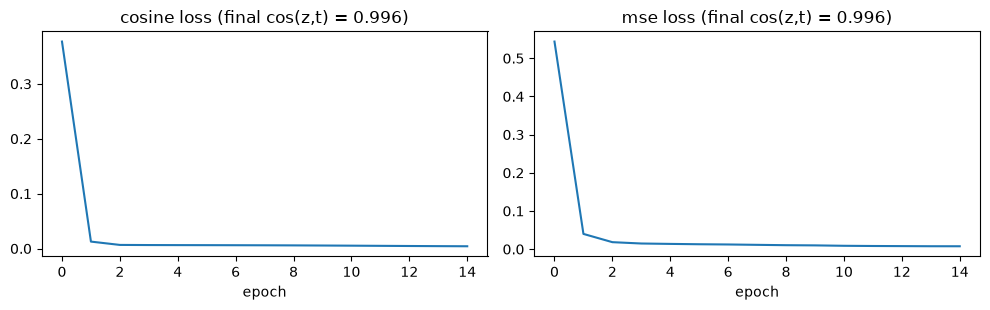

In [10]:
def distil(loss_name, epochs=15, bs=256):
    torch.manual_seed(0)
    f, g = make_student().to(dev), nn.Linear(B, T.shape[1]).to(dev)
    opt = torch.optim.Adam([*f.parameters(), *g.parameters()], 1e-3)
    xs, ts, hist = Xn[pool], T, []
    for ep in range(epochs):
        perm, tot = torch.randperm(len(xs)), 0
        for i in range(0, len(xs), bs):
            j = perm[i:i+bs]; z = g(f(xs[j].to(dev))); t = ts[j].to(dev)
            loss = F.mse_loss(z, t) if loss_name == "mse" else (1 - F.cosine_similarity(z, t)).mean()
            opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item() * len(j)
        hist.append(tot / len(xs))
    with torch.no_grad():
        cos = torch.cat([F.cosine_similarity(g(f(xs[i:i+1024].to(dev))), ts[i:i+1024].to(dev)).cpu() for i in range(0, len(xs), 1024)]).mean().item()
    return f.cpu(), hist, cos

students = {}
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
for k, name in enumerate(["cosine", "mse"]):
    students[name], hist, cos = distil("cos" if name == "cosine" else "mse")
    ax[k].plot(hist); ax[k].set(title=f"{name} loss (final cos(z,t) = {cos:.3f})", xlabel="epoch")
plt.tight_layout(); plt.show()

## 7. Phase 2 — multi-task fine-tuning


In [11]:
TASKS = ["cloud", "water"]
idx = {(t, s): np.where((meta.task == t) & (meta.split == s))[0] for t in TASKS for s in ["train", "val", "test"]}
Y = torch.tensor(meta.y.values)

def finetune(encoder, frac, epochs=10, bs=128, lam=(1.0, 1.0), y=Y):
    torch.manual_seed(0)
    f = (make_student() if encoder is None else __import__("copy").deepcopy(encoder)).to(dev)
    hs = nn.ModuleList([nn.Linear(B, 2) for _ in TASKS]).to(dev)
    opt = torch.optim.Adam([*f.parameters(), *hs.parameters()], 1e-3)
    tr_idx = [i[np.isin(meta.group.values[i], list(labelled[frac]))] for i in [idx[(t, "train")] for t in TASKS]]
    steps = max(len(i) for i in tr_idx) // bs + 1
    for _ in range(epochs):
        for _ in range(steps):
            loss = 0
            for k, i in enumerate(tr_idx):                        # one batch per task, losses summed
                j = rng.choice(i, bs)
                loss = loss + lam[k] * F.cross_entropy(hs[k](f(Xn[j].to(dev))), y[j].to(dev))
            opt.zero_grad(); loss.backward(); opt.step()
    return f.cpu().eval(), hs.cpu().eval()

@torch.no_grad()
def scores(f, hs, k, ids):
    return torch.softmax(hs[k](f(Xn[ids])), 1)[:, 1].numpy()

## 9. INT8 post-training quantisation
Each weight tensor is quantised symmetrically, $s=\max|w|/(2^{n-1}-1)$, $q=\mathrm{clip}(\mathrm{round}(w/s))$, $\hat w=s\,q$, with one scale per tensor or per output channel. No retraining (PTQ). Size = parameters × $\beta$ + 4 bytes per scale. Only weights are quantised here; activations stay in float.

In [14]:
def quantise(model, bits, per_channel):
    q, n_scales = __import__("copy").deepcopy(model), 0
    qmax = 2 ** (bits - 1) - 1
    with torch.no_grad():
        for name, p in q.named_parameters():
            if p.dim() < 2: continue                              # biases kept (small)
            m = p.abs().amax(dim=tuple(range(1, p.dim())), keepdim=True) if per_channel else p.abs().max()
            s = torch.where(m == 0, torch.ones_like(m), m) / qmax
            p.copy_(torch.clamp(torch.round(p / s), -qmax, qmax) * s); n_scales += s.numel()
    return q, n_scales

f, hs = models[("distil-cosine", 1.0)]
rows = []
for label, bits, pc in [("FP32", 32, None), ("INT8 per-tensor", 8, False), ("INT8 per-channel", 8, True), ("INT4 per-channel", 4, True)]:
    if bits == 32: fq, hq, ns = f, hs, 0
    else:
        (fq, n1), (hq, n2) = quantise(f, bits, pc), quantise(hs, bits, pc); ns = n1 + n2
    size = (n(f) + n(hs)) * bits / 8 + 4 * ns
    r = evaluate(fq, hq)
    rows.append(dict(model=label, KB=round(size / 1024, 1), fits_M=size <= M_BYTES, **{f"PR_AUC {t}": round(r[t]["PR_AUC"], 3) for t in TASKS}))
pd.DataFrame(rows)

,model,KB,fits_M,PR_AUC cloud,PR_AUC water
0,FP32,248.5,False,0.813,0.930
1,INT8 per-tensor,62.2,True,0.812,0.930
2,INT8 per-channel,63.0,True,0.813,0.930
3,INT4 per-channel,32.0,True,0.810,0.917
